# v12: v8 at S = 40, lambda = 0 and 1, on Kev 4B (model scale)

In [1]:
import json
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

# The `beta_ols` package lives next to this notebook in `train-notebooks/beta-training/`
BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
if not (BETA_TRAINING_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {BETA_TRAINING_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and the beta-training folder on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import reset_trainable, set_checkpointing, snapshot_trainable
from beta_train.reports import best_beta_table, best_table, comparison_table, eval_beta_table, mse_decomposition, per_dataset_table
from beta_train.runs import load_best
from beta_train.trainer import RunResult, load_run, run_training
from beta_train.validation import PopulationValidator, TrainingPathValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 4B backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to train jaredpalmer/kev-4b in bf16")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-4b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0
# Recompute activations in backward (less VRAM, slower). Memory-only: not part of a run's identity. Set True if the
# micro-chunk search below finds no size that fits
GRADIENT_CHECKPOINTING = False

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
set_checkpointing(kev_model, GRADIENT_CHECKPOINTING)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_4b_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

,kev_4b_train_mode
base_model,jaredpalmer/kev-4b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"131,170,816"
total_params,"4,336,922,112"
gradient_checkpointing,False
model_load_sec,2.717


Snapshotted 500 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Datasets this notebook uses; only these are loaded (the others are skipped to save time)
ITEM_DATASETS = [         # training items are built for these (training, gradient check, VRAM search)
    "wu2025",
    "berke2023",
]
VALIDATION_DATASETS = [   # validation runs on these
    "grummon2025",
    "kriner2026",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Validation uses the whole dataset. Training splits a dataset with several task variables (`v`) into one pseudo
# dataset per task ("<dataset>/<v>"), so an item holds one respondent's tasks of a single kind.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")

wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

berke2023/delivery_choice_v0: 3,014 respondents | 9,528 tasks | 1 regression(s)


berke2023/v0                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.1607  0.0095   0.3214
Fee L1 vs $0 ($1)                       -0.1509  0.0088  -0.3018
Fee L2 vs $0 ($3 fast / $5 meds)        -0.3298  0.0102  -0.6595
Fee L3 vs $0 ($5 fast / $10 meds)       -0.4978  0.0108  -0.9956
Wait L1 vs L0 (20m fast / 2h meds)      -0.0631  0.0107  -0.1261
Wait L2 vs L0 (30m fast / 6h meds)      -0.2082  0.0106  -0.4164
Wait L3 vs L0 (45m fast / 1d meds)      -0.3419  0.0124  -0.6837
sigma_y                                  0.5000     NaN      NaN
n_rows                               19056.0000     NaN      NaN

berke2023/delivery_choice_v1: 3,323 respondents | 11,481 tasks | 1 regression(s)


berke2023/v1                 
                                           beta      se std_beta
Drone privacy: YES vs NO                 0.2242  0.0088   0.4484
Fee L1 vs $0 ($1)                       -0.0822  0.0087  -0.1644
Fee L2 vs $0 ($3 fast / $5 meds)        -0.2964  0.0096  -0.5929
Fee L3 vs $0 ($5 fast / $10 meds)       -0.5023  0.0108  -1.0045
Wait L1 vs L0 (20m fast / 2h meds)      -0.0743  0.0095  -0.1487
Wait L2 vs L0 (30m fast / 6h meds)      -0.1924  0.0095  -0.3848
Wait L3 vs L0 (45m fast / 1d meds)      -0.2638  0.0102  -0.5276
sigma_y                                  0.5000     NaN      NaN
n_rows                               22962.0000     NaN      NaN

... (5 outputs left out)

grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

kriner2026: 1,000 respondents | 5,000 tasks | 1 regression(s)


kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

TRAIN_DATASETS = ['wu2025', 'berke2023/delivery_choice_v0', 'berke2023/delivery_choice_v1', 'berke2023/delivery_choice_v2', 'berke2023/delivery_choice_v3']


# Model, validators, and training items

In [4]:
# One validator per VALIDATION_DATASETS entry (population OLS from the dataset's module); pick how inference runs
VALIDATOR_KIND = "fused"   # "fused": LoRA merged + fused kernels + CUDA graphs, persona states shared
                           # "training_path": the training forward in eval mode, LoRA unmerged (no merge/offload/capture)
# "fused" per-GPU-batch inference budgets: lower them if validation runs out of memory (bigger models), raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
# "fused" CUDA-graph limits inside a batch: each batch runs as passes of at most GRAPH_ROWS question rows (and
# GRAPH_TOKENS rows x positions) and GRAPH_STATES persona states, so these cap a pass however large the budgets above
# are. Comments: the eval default (data.base.EVAL_GRAPH_LIMITS, used when graph_limits is not passed)
VALIDATION_GRAPH_LIMITS = {
    "BANK_WIDTH": 512,       # default 512 (unchanged): positions per stored persona state
    "GRAPH_STATE": 512,      # default 512 (unchanged): longest persona state that is graphed
    "GRAPH_STATES": 16,      # default 8: persona states per state pass
    "GRAPH_ROWS": 64,        # default 16: question rows per row pass
    "GRAPH_TOKENS": 40960,   # default 16384: rows x positions per row pass
}
# "training_path" items (data rows) per forward pass (no gradients, so far above the training micro-chunk)
VALIDATION_EVAL_CHUNK = 32

validators = {}
if VALIDATOR_KIND == "fused":
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = PopulationValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            max_questions=VALIDATION_MAX_QUESTIONS,
            max_chars=VALIDATION_MAX_CHARS,
            graph_limits=VALIDATION_GRAPH_LIMITS,
        )
elif VALIDATOR_KIND == "training_path":
    # The training path runs on items (tokenized respondents), cached on disk like the training items
    validation_modules = {}
    for dataset_name in VALIDATION_DATASETS:
        validation_modules[dataset_name] = beta_ols.DATASET_MODULES[dataset_name]
    validation_items, validation_items_report = build_items_cached(kev_model, validation_modules, choice_dfs, cache_dir=CACHE_DIR)
    display(validation_items_report)
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = TrainingPathValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            validation_items[dataset_name],
            eval_chunk=VALIDATION_EVAL_CHUNK,
        )
else:
    raise ValueError(f"VALIDATOR_KIND must be 'fused' or 'training_path', got {VALIDATOR_KIND!r}")
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,graph_limits,prep_sec
validator,,,,,,,,
grummon2025,fused,33798,4906,grummon2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",6.131
kriner2026,fused,5000,990,kriner2026,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",1.106


In [5]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,source
validator,
grummon2025,computed
kriner2026,computed


,grummon2025,kriner2026
kl_loss,1.0998,0.8107
beta_mse,0.0211,0.0041
beta_mae,0.1233,0.0513
beta_mape_pct,146.0585,63.9489
spearman_rho,0.8000,0.8951
eval_prep_sec,0.5373,0.0542
eval_gpu_sec,313.7828,38.2256
eval_wall_sec,317.6025,40.5354
eval_ms_per_task,9.3971,8.1071


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.2495,0.0651,0.0651
HighIn vs Positive,grummon2025,0.0541,-0.2079,-0.2620,0.2620
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.3053,0.1265,0.1265
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0016,-0.1211,0.1211
Spectrum vs Positive,grummon2025,0.1083,0.0665,-0.0418,0.0418


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Airline: Frontier,kriner2026,-0.0854,-0.1804,-0.0950,0.0950
Airline: Southwest,kriner2026,-0.0238,0.0220,0.0458,0.0458
Airline: United,kriner2026,-0.0220,-0.0166,0.0054,0.0054
Fuel: Sustainable aviation fuel,kriner2026,0.0691,0.0995,0.0305,0.0305
Baggage: Checked bag+carry-on,kriner2026,0.0561,0.0877,0.0316,0.0316
Baggage: Personal item only,kriner2026,-0.1393,-0.1861,-0.0468,0.0468
Space: Extra legroom,kriner2026,0.0653,0.1244,0.0592,0.0592
Seat: Middle,kriner2026,-0.0906,-0.0841,0.0065,0.0065
Seat: Window,kriner2026,0.0384,0.0087,-0.0297,0.0297


In [6]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were already
# built for this data, tokenizer, and code; Kev's prepared targets are checked against each respondent's beta part

item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
wu2025,18591,cache
berke2023/delivery_choice_v0,9528,cache
berke2023/delivery_choice_v1,11481,cache
berke2023/delivery_choice_v2,7269,cache
berke2023/delivery_choice_v3,8019,cache


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025
berke2023/delivery_choice_v0,9528,3014,berke2023/v0
berke2023/delivery_choice_v1,11481,3323,berke2023/v1
berke2023/delivery_choice_v2,7269,2381,berke2023/v2
berke2023/delivery_choice_v3,8019,2577,berke2023/v3


# Find max micro chunk

In [7]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) chunks of these datasets
SEARCH_GRADIENT_CHECKPOINTING = GRADIENT_CHECKPOINTING   # search with the setting you train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1117 09:49:36.939880054 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 58720256 bytes (free: 5636096, total: 33733804032).
[W1117 09:49:36.942174039 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 29360128 bytes (free: 5636096, total: 33733804032).
[W1117 09:49:36.942265749 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 29360128 bytes (free: 5636096, total: 33733804032).
[W1117 09:49:40.274591862 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 44040192 bytes (free: 37093376, total: 33733804032).
[W1117 09:49:40.296304349 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 12582912 bytes (free: 16121856, total: 33733804032).
[W1117 09:49:40.296395590 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on devi

,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,berke2023/delivery_choice_v3,longest state + longest branch + most questions,510,True,12.83,40.8
1,1,berke2023/delivery_choice_v3,longest branch + most questions,502,True,12.76,40.6
2,1,berke2023/delivery_choice_v2,longest state + longest branch + most questions,483,True,12.68,40.4
3,2,berke2023/delivery_choice_v3,longest state + longest branch + most questions,1020,True,16.93,53.9
4,2,berke2023/delivery_choice_v3,most padded tokens each,1020,True,16.93,53.9
5,2,berke2023/delivery_choice_v3,longest branch + most questions,1004,True,16.78,53.4
6,4,berke2023/delivery_choice_v3,longest state + longest branch + most questions,2040,True,24.92,79.3
7,4,berke2023/delivery_choice_v3,most padded tokens each,2040,True,24.92,79.3
8,4,berke2023/delivery_choice_v3,longest branch + most questions,2008,True,24.66,78.5
9,5,berke2023/delivery_choice_v3,longest state + longest branch + most questions,2550,True,28.72,91.4


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 5


# Train

In [7]:
MAX_FITTING_MICRO_CHUNK = 4
GRADIENT_CHECKPOINTING

False

In [8]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v12-wu-berke-scale-4b"
# Question of this notebook: model scale. v8's S = 40 runs at lambda = 0 and 1 (Kev 800M), repeated on Kev 4B with
# every training setting unchanged; the scale cell at the end compares the two models
V8_RUNS_DIR = BETA_TRAINING_DIR / "runs" / "train-beta-v8-wu-berke-sample-lrscale-800m"
RUNS_DIR = BETA_TRAINING_DIR / "runs" / NOTEBOOK
# ONE validator's column picks checkpoints/best.pt: "kriner2026/val_loss" = Kriner's KL + beta_lambda * std beta MSE
# (the run's own training loss form). Grummon 2025 is not used for selection: its values at the best step are a held-out
# check. Other choices: any "kriner2026/<metric>" column, e.g. "kriner2026/beta_mse" ("min"), "kriner2026/spearman_rho" ("max").
BEST_METRIC = "kriner2026/val_loss"
BEST_MODE = "min"

# Base run settings; each run cell below sets the sample size (tasks = training items per step, the same for every
# training dataset; with it, the peak LR and the validation steps) and beta_lambda. Training datasets keep their
# natural mix: each contributes ceil(its tasks / S) samples per epoch.
BETA_LAMBDA = 1.0
NUM_EPOCHS = 1
# Peak LR = BASE_LR_PER_TASK x sqrt(sample size in tasks = training items per step), for any mix of training datasets.
# The base is v4's 2e-5 per respondent converted to tasks: v4's items were whole Wu respondents (10 tasks each), so
# 2e-5 x sqrt(S / 10) = (2e-5 / sqrt(10)) x sqrt(S); S = 160 tasks = v4's S = 16 respondents at LR 8e-5
BASE_LR_PER_TASK = 2e-5 / math.sqrt(10)
# Rows (training items) seen between validations, per validator, so every sample size validates at the same points in
# the epoch (all validators also run at step 0 and the last step). 1,280 / 6,400 rows = every 20 / 100 steps at S = 64.
# kriner2026 picks best.pt, so it runs often; grummon2025 is the held-out check (best.pt is validated on it at the end
# if it did not run at that step)
EVAL_EVERY_ROWS_BY_VALIDATOR = {"kriner2026": 1280, "grummon2025": 6400}
BASE_SAMPLE_SIZE = 40
BASE_CONFIG = TrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={ts: BASE_SAMPLE_SIZE for ts in TRAIN_DATASETS},
    beta_lambda=BETA_LAMBDA,
    lr=scale_lr_for_sample_size(BASE_LR_PER_TASK, BASE_SAMPLE_SIZE),
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator={"kriner2026": 32, "grummon2025": 160},   # = EVAL_EVERY_ROWS_BY_VALIDATOR / 40
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)

In [9]:
def make_run_config(sample_size: int, beta_lambda: float) -> TrainConfig:
    # BASE_CONFIG with this beta_lambda, this sample size for every training dataset, its sqrt-scaled peak LR, and
    # validation steps = rows between validations / S
    lr = scale_lr_for_sample_size(BASE_LR_PER_TASK, sample_size)
    eval_every_by_validator = {}
    for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
        eval_every_by_validator[validator_name] = max(1, round(eval_every_rows / sample_size))
    sample_size_by_dataset = {}
    for dataset_name in TRAIN_DATASETS:
        sample_size_by_dataset[dataset_name] = sample_size
    return replace(
        BASE_CONFIG,
        beta_lambda=beta_lambda,
        sample_size_by_dataset=sample_size_by_dataset,
        lr=lr,
        eval_every_by_validator=eval_every_by_validator,
    )


def run_name(config: TrainConfig) -> str:
    # Run folder name from the settings this notebook varies: lambda, peak LR, sample size (rows per step), epochs
    sample_sizes = sorted(set(config.as_dict()["sample_size_by_dataset"].values()))
    sample_size_text = "-".join(str(size) for size in sample_sizes)
    return f"lambda={config.beta_lambda:g}_lr={config.lr:g}_S={sample_size_text}_ep={config.num_epochs}"

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": VALIDATOR_KIND,
    "validation_graph_limits": VALIDATION_GRAPH_LIMITS,
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

,base_config
train_datasets,"[wu2025, berke2023/delivery_choice_v0, berke20..."
sample_size_by_dataset,"{'wu2025': 40, 'berke2023/delivery_choice_v0':..."
beta_lambda,1.0
lr,0.00004
num_epochs,1
eval_every_by_validator,"{'kriner2026': 32, 'grummon2025': 160}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,4
gradient_checkpointing,False


,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.09976,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,0.81071,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,NaN,317.60245,40.53544,0.00000
32,1,1280,0.67058,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.66585,0.00916,0.66585,0.00229,0.04065,56.57097,0.93706,0.00001,NaN,42.82822,124.94007
64,1,2560,0.55995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.61159,0.00894,0.61159,0.00224,0.03819,50.45169,0.97203,0.00002,NaN,43.28250,249.92216
96,1,3840,0.56174,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.59293,0.00400,0.59293,0.00100,0.02497,41.49211,0.93706,0.00003,NaN,43.26472,376.46132


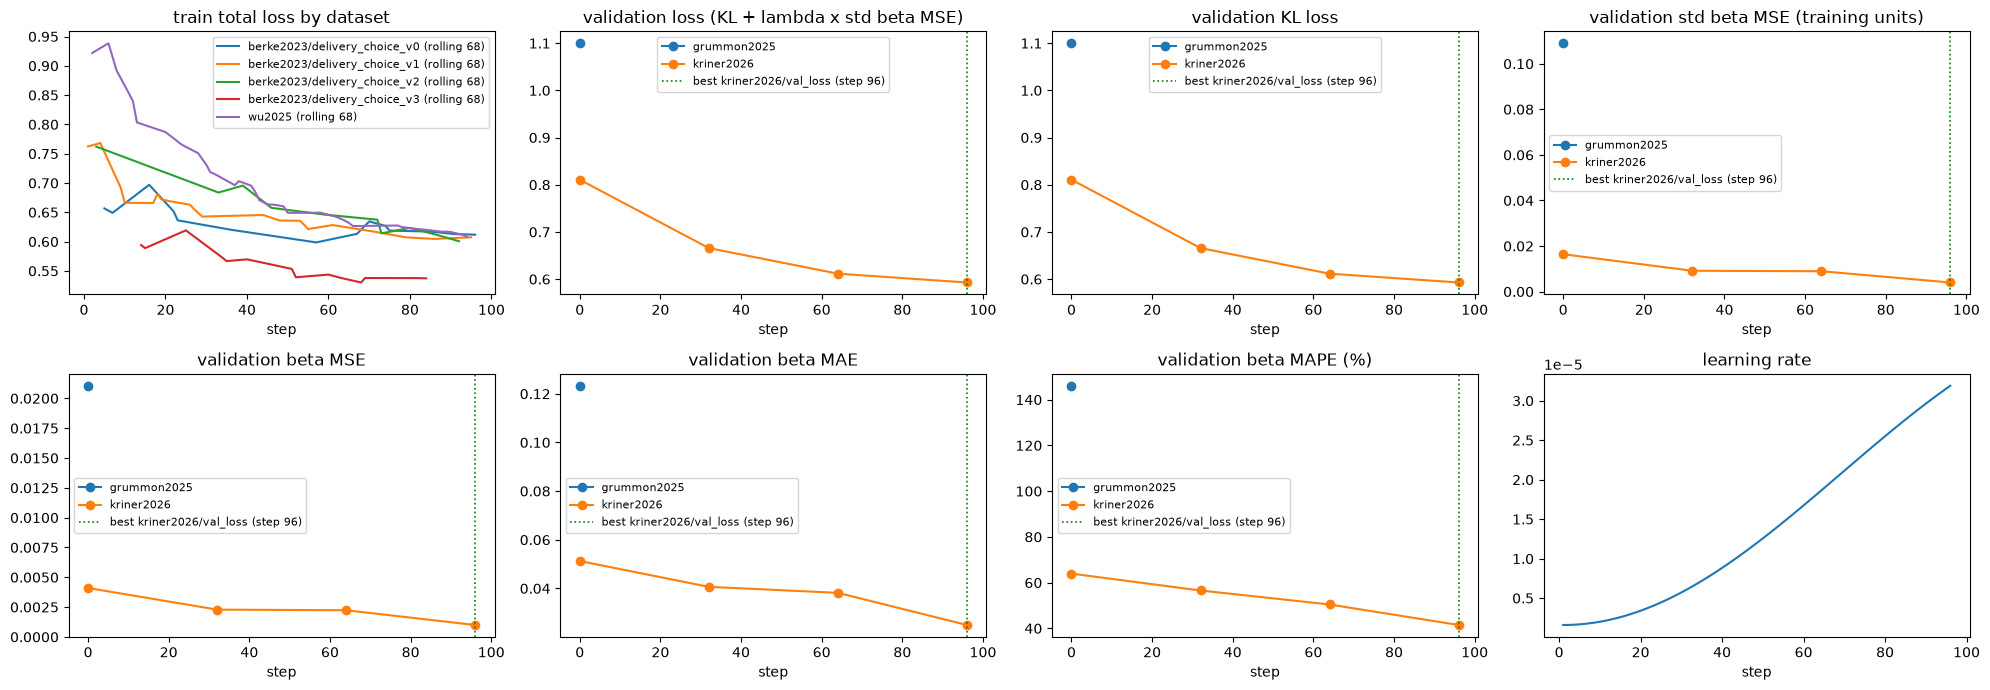

In [ ]:
# Sample size 40 tasks per step, beta_lambda = 0
sample_size = 40
beta_lambda = 0.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.20875,0.10899,1.09976,0.02105,0.12329,146.05853,0.80000,0.82712,0.01641,0.81071,0.00410,0.05127,63.94891,0.89510,NaN,317.36416,40.54820,0.00000
32,1,1280,0.91156,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.69887,0.00817,0.69070,0.00204,0.03912,57.45217,0.93706,0.00001,NaN,43.09179,125.28476
64,1,2560,0.69822,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.63061,0.00615,0.62446,0.00154,0.03200,53.36866,0.96503,0.00002,NaN,42.90841,250.41643
96,1,3840,0.73028,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.61844,0.00604,0.61240,0.00151,0.03477,50.19281,0.92308,0.00003,NaN,43.22151,376.91639
128,1,5120,0.69804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.61735,0.00877,0.60858,0.00219,0.04028,55.45364,0.92308,0.00004,NaN,43.15100,501.57191
160,1,6400,0.69669,0.87978,0.03180,0.84798,0.00614,0.06892,75.08174,0.90000,0.59131,0.00407,0.58724,0.00102,0.02652,47.07034,0.93007,0.00004,318.64900,42.37763,628.97866
192,1,7680,0.70985,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.60550,0.00719,0.59831,0.00180,0.03622,50.81051,0.95105,0.00004,NaN,42.96981,753.63372
224,1,8960,0.63808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.61096,0.00583,0.60512,0.00146,0.03292,54.93581,0.92308,0.00004,NaN,42.89032,880.79197
256,1,10240,0.68002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.59424,0.00533,0.58891,0.00133,0.02773,50.41009,0.92308,0.00004,NaN,42.38894,1002.50449


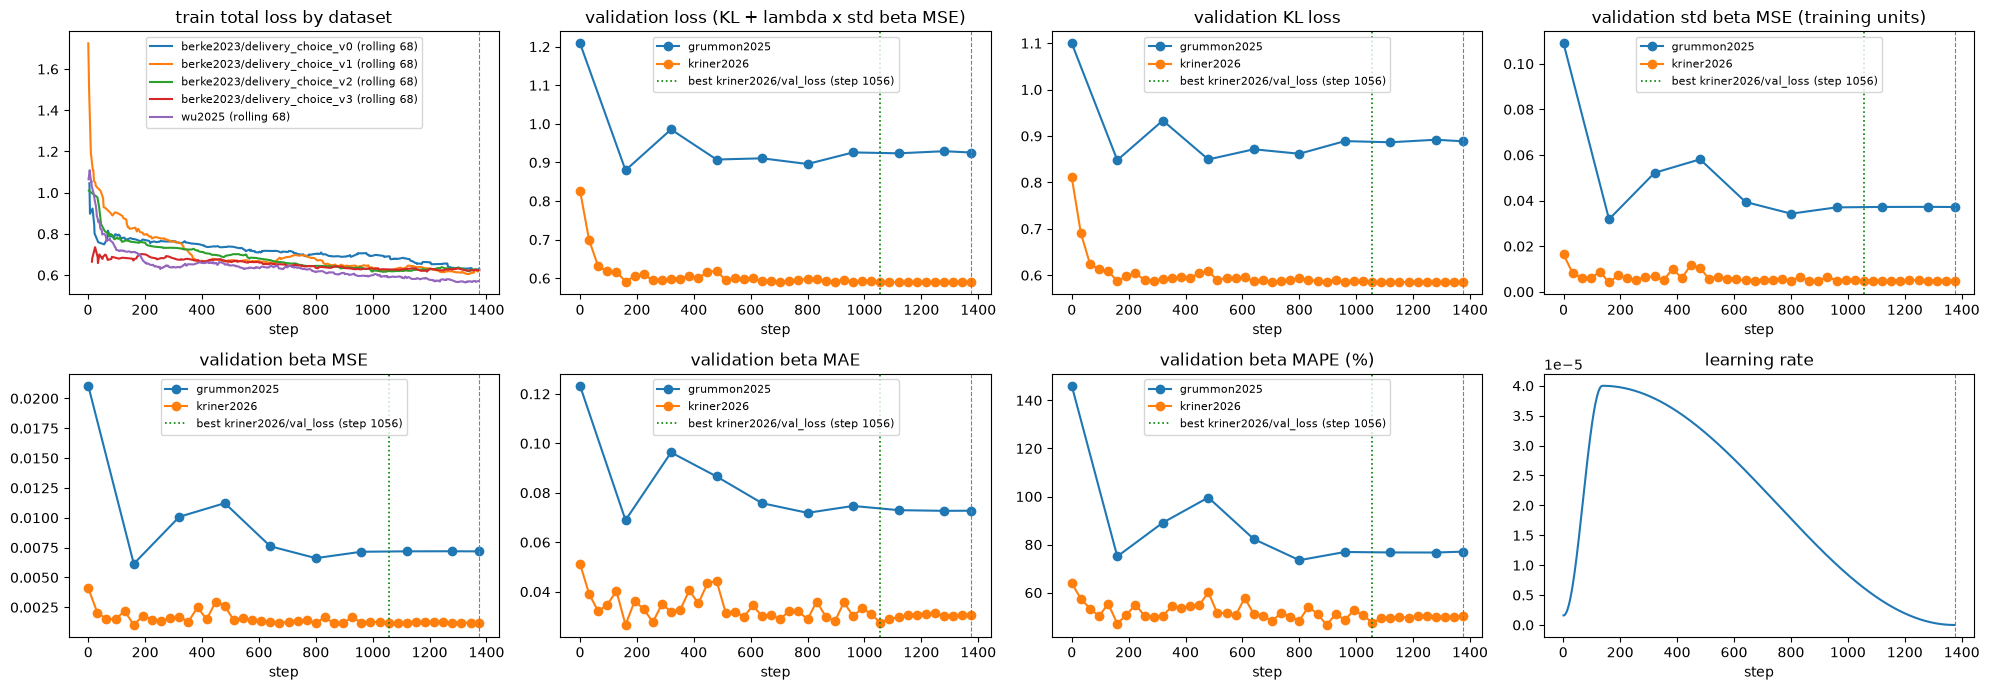

best.pt (step 1056) validated at the end on: grummon2025


In [10]:
# Sample size 40 tasks per step, beta_lambda = 1
sample_size = 40
beta_lambda = 1.0
run_config = make_run_config(sample_size, beta_lambda)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

# Model scale: 800M (v8) vs 4B

In [ ]:
# Model scale: v8's Kev 800M runs vs this notebook's Kev 4B runs at the same settings (S = 40, lambda = 0 and 1).
# Per validator: the step with that validator's lowest val_loss (its KL and beta MSE there), and the lowest beta MSE
SCALE_SAMPLE_SIZE = 40
SCALE_LAMBDAS = [0.0, 1.0]
MODEL_RUN_DIRS = {"kev-0.8b (v8)": V8_RUNS_DIR, "kev-4b (v12)": RUNS_DIR}

scale_rows = []
for model_label, model_runs_dir in MODEL_RUN_DIRS.items():
    for beta_lambda in SCALE_LAMBDAS:
        run_dir = model_runs_dir / run_name(make_run_config(SCALE_SAMPLE_SIZE, beta_lambda))
        run_info = json.loads((run_dir / "run.json").read_text())
        if run_info["status"] != "finished":
            print(f"skipped (status {run_info['status']}): {run_dir}")
            continue
        val_history = pd.read_csv(run_dir / "val_history.csv")
        for validator_name in VALIDATION_DATASETS:
            validator_rows = val_history.dropna(subset=[f"{validator_name}/val_loss"])
            picked = validator_rows.loc[validator_rows[f"{validator_name}/val_loss"].idxmin()]
            scale_rows.append({
                "validator": validator_name,
                "model": model_label,
                "lambda": beta_lambda,
                "step0_beta_mse": validator_rows[f"{validator_name}/beta_mse"].iloc[0],
                "picked_step": picked["step"],
                "kl_at_picked": picked[f"{validator_name}/kl_loss"],
                "beta_mse_at_picked": picked[f"{validator_name}/beta_mse"],
                "lowest_beta_mse": validator_rows[f"{validator_name}/beta_mse"].min(),
            })
scale_df = pd.DataFrame(scale_rows)
for validator_name in VALIDATION_DATASETS:
    print(validator_name)
    validator_table = scale_df[scale_df["validator"] == validator_name].drop(columns="validator")
    display(validator_table.set_index(["model", "lambda"]).round(5))

In [ ]:
# Compare finished runs: final validation metrics, per-dataset train losses, and each validator's betas
display(comparison_table(runs, step0_validation).round(5))
display(per_dataset_table(runs).round(5))
for dataset_name in validators:
    display(eval_beta_table(runs, step0_validation, dataset_name).round(4))

# The same runs at their best validation (by each run's best metric)
display(best_table(runs).round(5))
for dataset_name in validators:
    display(best_beta_table(runs, step0_validation, dataset_name).round(4))

In [ ]:
# Load every saved run of this notebook from disk (no training; works in a fresh kernel after the setup cells)
runs = {}
for saved_run_dir in sorted(RUNS_DIR.iterdir()):
    runs[saved_run_dir.name] = load_run(saved_run_dir)
display(pd.DataFrame([run.summary for run in runs.values()]).set_index("label"))

In [ ]:
# Decompose each validator's beta MSE into per-beta squared errors across runs
for dataset_name in validators:
    display(mse_decomposition(runs, step0_validation, dataset_name).round(5))